# 00 · Môi trường & hồ sơ dữ liệu

Notebook này kiểm tra môi trường, kiểm kê bộ dữ liệu thật và vẽ những phân bố đầu tiên.

**Engine của bản chạy này:** DuckDB + Parquet trên local filesystem. Đây là bản *lite* để chạy được ngay trên Windows, thay cho Hive/Spark/HDFS trong bài báo. Luồng dữ liệu, schema, truy vấn và ML vẫn giữ nguyên; phần khác biệt được ghi ở `README.md`.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from config import *
ensure_dirs()
setup_matplotlib()

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

print("ROOT:", ROOT)
print(env_note())


ROOT: D:\projectDW\agri-dwh


{'python': '3.12.6', 'pandas': '3.1.1', 'duckdb': '2.0.0', 'scikit_learn': '1.9.1', 'database': 'D:\\projectDW\\agri-dwh\\warehouse\\agri_dwh.duckdb', 'cwd': 'D:\\projectDW\\agri-dwh\\notebooks'}


## 1. Kiểm kê file dữ liệu

Bộ dữ liệu đã tải gồm bản hourly, daily, yield và dimension. Các con số dưới đây được đếm lại từ file, không lấy từ README.


In [2]:
files = [
    CSV_LOCATION,
    CSV_DAILY,
    CSV_HOURLY,
    CSV_YIELD,
    CSV_BENCHMARK,
]
rows = []
for path in files:
    if not path.exists():
        rows.append({"file": path.name, "rows": None, "MB": None, "status": "missing"})
        continue
    n = duckdb.sql(
        f"SELECT COUNT(*) FROM read_csv_auto('{path.as_posix()}')"
    ).fetchall()[0][0]
    rows.append({
        "file": path.name,
        "rows": n,
        "MB": round(path.stat().st_size / 1_000_000, 2),
        "status": "ok",
    })

inventory = pd.DataFrame(rows)
display(inventory.style.format({"rows": "{:,}", "MB": "{:.2f}"}))


,file,rows,MB,status
0,dim_location.csv,12,0.00,ok
1,fact_weather_daily.csv,"43,836",2.46,ok
2,fact_weather_hourly.csv,"1,052,064",61.27,ok
3,fact_cereal_annual.csv,100,0.00,ok
4,benchmark_like_hourly.csv,"1,052,064",63.26,ok


## 2. Xem nhanh các bảng

Ba bảng chính: dimension địa điểm, năng suất theo quốc gia/năm, và mẫu dữ liệu hourly.


In [3]:
con = duckdb.connect()

dim = con.execute(
    f"SELECT * FROM read_csv_auto('{CSV_LOCATION.as_posix()}', header=true)"
).df()
yield_df = con.execute(
    f"SELECT * FROM read_csv_auto('{CSV_YIELD.as_posix()}', header=true) ORDER BY country_iso3, year"
).df()
hourly_sample = con.execute(
    f"SELECT * FROM read_csv_auto('{CSV_HOURLY.as_posix()}', header=true) LIMIT 6"
).df()

display(dim)
display(yield_df.head(8))
display(hourly_sample)


,location_id,name,country_iso3,country_name,latitude,longitude,crop_system
0,VN-CT,Can Tho,VNM,Vietnam,10.03,105.78,rice
1,VN-HD,Hai Duong,VNM,Vietnam,20.94,106.33,rice
2,IN-PB,"Ludhiana, Punjab",IND,India,30.90,75.85,wheat-rice
3,US-IA,"Story City, Iowa",USA,United States,42.19,-93.59,maize
4,US-KS,"Garden City, Kansas",USA,United States,37.97,-100.87,wheat
5,BR-PR,"Cascavel, Parana",BRA,Brazil,-24.96,-53.46,soy-maize
6,FR-CVL,"Chartres, Beauce",FRA,France,48.45,1.49,wheat
7,KE-NKR,Nakuru,KEN,Kenya,-0.30,36.07,maize
8,MA-MEK,Meknes,MAR,Morocco,33.89,-5.55,wheat
9,RU-ROS,Rostov-on-Don,RUS,Russia,47.24,39.71,wheat


,country_iso3,country_name,year,cereal_area_ha,cereal_production_mt,cereal_yield_kg_per_ha
0,ARG,Argentina,2015,10709207.0,53364962.0,4983.1
1,ARG,Argentina,2016,13364925.0,68228187.0,5105.0
2,ARG,Argentina,2017,14391296.0,76520392.0,5317.1
3,ARG,Argentina,2018,15341115.0,71533692.0,4662.9
4,ARG,Argentina,2019,15952507.0,83934094.0,5261.5
5,ARG,Argentina,2020,16259386.0,83569978.0,5139.8
6,ARG,Argentina,2021,17041102.0,92198347.0,5410.4
7,ARG,Argentina,2022,17004207.0,81989897.0,4821.7


,timestamp,location_id,t2m_c,rh2m_pct,precip_mm_h,ws2m_ms,soil_wetness_root,soil_wetness_top
0,2015-01-01 00:00:00,VN-CT,22.15,88.24,0.0,1.59,0.6,0.57
1,2015-01-01 01:00:00,VN-CT,22.10,89.07,0.0,1.45,0.6,0.57
2,2015-01-01 02:00:00,VN-CT,22.04,89.81,0.0,1.36,0.6,0.57
3,2015-01-01 03:00:00,VN-CT,21.92,90.54,0.0,1.31,0.6,0.57
4,2015-01-01 04:00:00,VN-CT,21.49,92.55,0.0,1.11,0.6,0.57
5,2015-01-01 05:00:00,VN-CT,20.85,94.86,0.0,1.09,0.6,0.57


## 3. Hồ sơ dữ liệu hourly

Kiểm tra số dòng, khoảng thời gian, khoảng giá trị và số giá trị thiếu. Đây là bước data profiling trước khi xây kho.


In [4]:
profile = con.execute(
    f"""
    SELECT COUNT(*) AS rows,
           COUNT(DISTINCT location_id) AS locations,
           MIN(CAST(timestamp AS TIMESTAMP)) AS min_time,
           MAX(CAST(timestamp AS TIMESTAMP)) AS max_time,
           MIN(t2m_c) AS min_t2m,
           MAX(t2m_c) AS max_t2m,
           MIN(soil_wetness_root) AS min_soil,
           MAX(soil_wetness_root) AS max_soil,
           MIN(precip_mm_h) AS min_precip,
           MAX(precip_mm_h) AS max_precip,
           SUM(CASE WHEN t2m_c IS NULL OR soil_wetness_root IS NULL
                     OR precip_mm_h IS NULL THEN 1 ELSE 0 END) AS null_cells
    FROM read_csv_auto('{CSV_HOURLY.as_posix()}', header=true)
    """
).df()
display(profile.T.rename(columns={0: "value"}))


,value
rows,1052064
locations,12
min_time,2015-01-01 00:00:00
max_time,2024-12-31 23:00:00
min_t2m,-32.88
max_t2m,48.46
min_soil,0.24
max_soil,1.0
min_precip,0.0
max_precip,137.93


## 4. Khí hậu theo tháng

Tổng hợp 1 triệu dòng thành chuỗi tháng để thấy mùa vụ: nhiệt độ, độ ẩm đất và mưa.


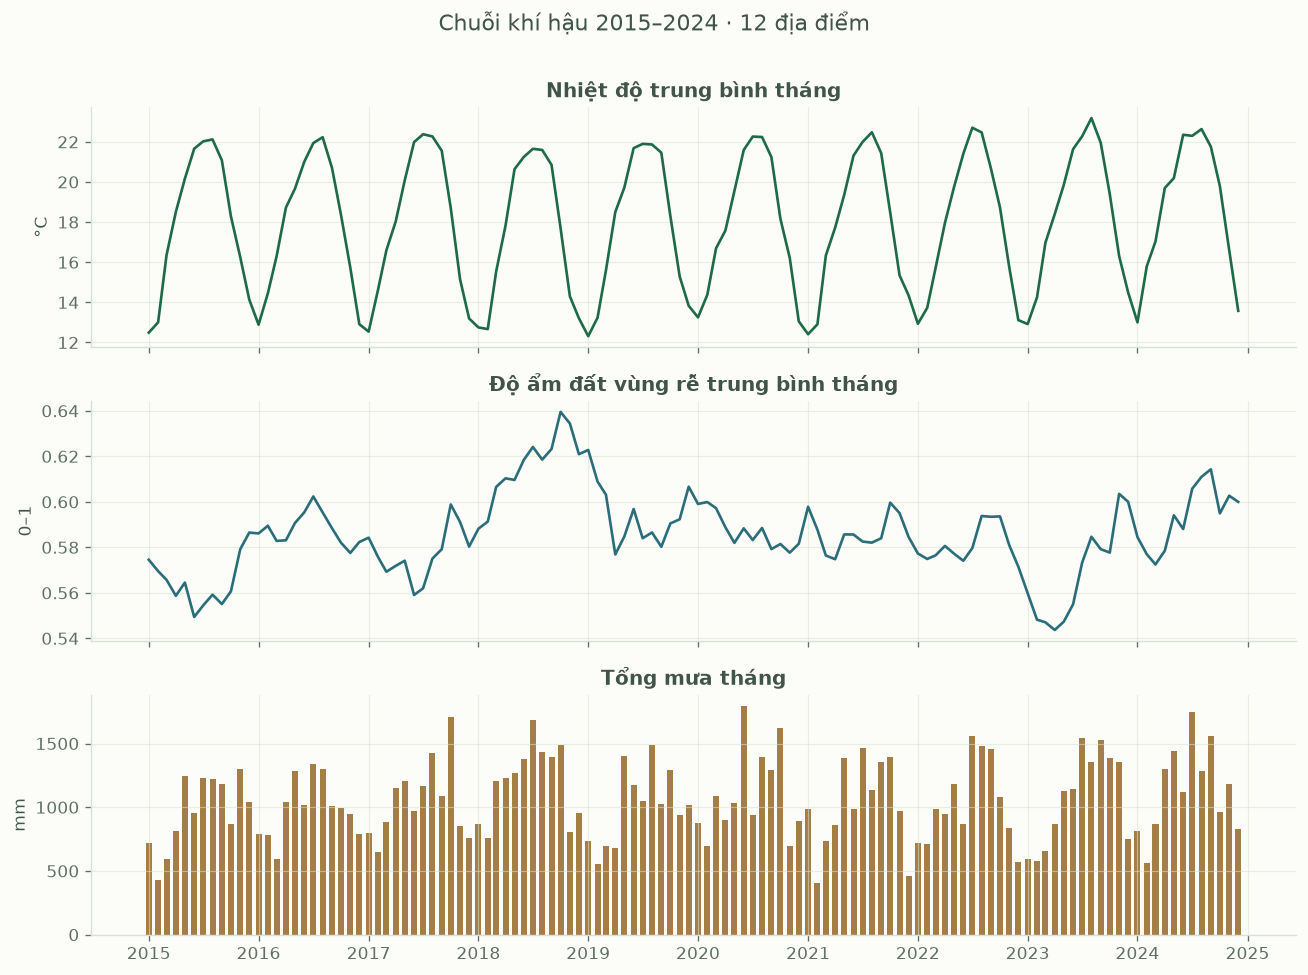

In [5]:
monthly = con.execute(
    f"""
    SELECT date_trunc('month', CAST(timestamp AS TIMESTAMP)) AS month,
           AVG(t2m_c) AS temp_c,
           AVG(soil_wetness_root) AS soil,
           SUM(precip_mm_h) AS rain_mm
    FROM read_csv_auto('{CSV_HOURLY.as_posix()}', header=true)
    GROUP BY 1 ORDER BY 1
    """
).df()
monthly["month"] = pd.to_datetime(monthly["month"])

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].plot(monthly["month"], monthly["temp_c"], color=PALETTE["green"], linewidth=1.6)
axes[0].set_ylabel("°C")
axes[0].set_title("Nhiệt độ trung bình tháng")
axes[1].plot(monthly["month"], monthly["soil"], color=PALETTE["teal"], linewidth=1.6)
axes[1].set_ylabel("0–1")
axes[1].set_title("Độ ẩm đất vùng rễ trung bình tháng")
axes[2].bar(monthly["month"], monthly["rain_mm"], width=20, color=PALETTE["gold"], alpha=.8)
axes[2].set_ylabel("mm")
axes[2].set_title("Tổng mưa tháng")
fig.suptitle("Chuỗi khí hậu 2015–2024 · 12 địa điểm", fontsize=13, y=1.01)
fig.tight_layout()
save_figure(fig, "00_monthly_climate.png")
plt.show()


## 5. Khác biệt giữa các địa điểm

Lấy mẫu 300.000 dòng để so sánh nhiệt độ và độ ẩm đất trung bình theo địa điểm. Đây là lý do cần `dim_location` thay vì một cột `location` dạng chuỗi tự do.


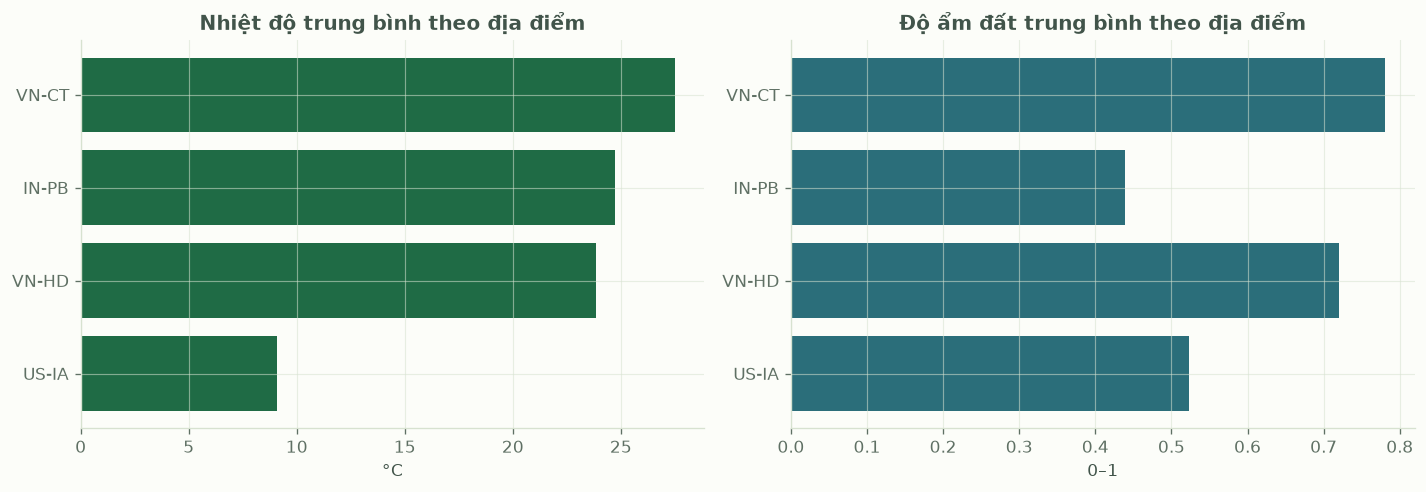

In [6]:
sample = con.execute(
    f"""
    SELECT location_id, t2m_c, soil_wetness_root, precip_mm_h
    FROM read_csv_auto('{CSV_HOURLY.as_posix()}', header=true)
    LIMIT 300000
    """
).df()
means = sample.groupby("location_id")[["t2m_c", "soil_wetness_root"]].mean().sort_values("t2m_c")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].barh(means.index, means["t2m_c"], color=PALETTE["green"])
axes[0].set_title("Nhiệt độ trung bình theo địa điểm")
axes[0].set_xlabel("°C")
axes[1].barh(means.index, means["soil_wetness_root"], color=PALETTE["teal"])
axes[1].set_title("Độ ẩm đất trung bình theo địa điểm")
axes[1].set_xlabel("0–1")
fig.tight_layout()
save_figure(fig, "00_location_means.png")
plt.show()


## 6. Năng suất theo quốc gia

Năng suất là số liệu **quốc gia theo năm**, không phải từng thửa. Đây là nhãn cho mô hình ở notebook 03.


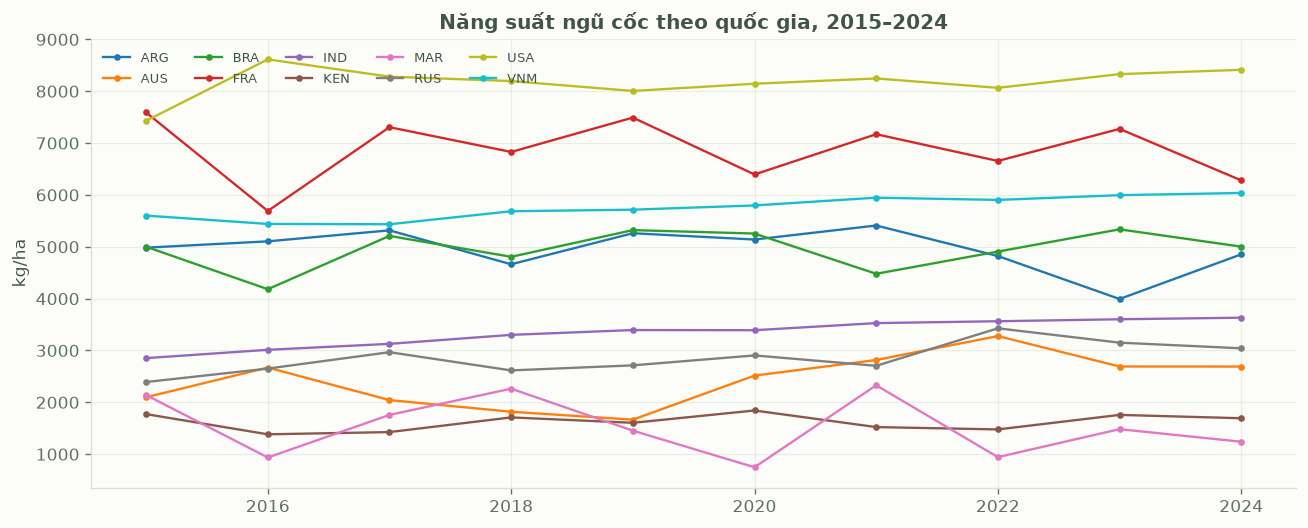

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for country, group in yield_df.groupby("country_iso3"):
    ax.plot(group["year"], group["cereal_yield_kg_per_ha"], marker="o", markersize=3,
            linewidth=1.4, label=country)
ax.set_title("Năng suất ngũ cốc theo quốc gia, 2015–2024")
ax.set_ylabel("kg/ha")
ax.legend(ncol=5, fontsize=8, loc="upper left")
fig.tight_layout()
save_figure(fig, "00_yield_countries.png")
plt.show()


## Kết luận notebook 00

- Có **1.052.064** dòng hourly, **12 địa điểm**, phủ **2015–2024**.
- Không có giá trị thiếu ở các biến chính trong lần tải này.
- Dữ liệu khí hậu là tái phân tích NASA POWER; năng suất là số liệu quốc gia World Bank.
- Bước tiếp theo: notebook `01_batch_dwh.ipynb` sẽ nạp dữ liệu vào DuckDB, ghi Parquet phân vùng và chạy 4 truy vấn benchmark.

Đóng kết nối DuckDB ở cuối notebook để tránh khóa file.


In [8]:
con.close()
